In [1]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import new_calcium_model, simulate_dipole, MPIBackend

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology
 
# import pandas as pd
from scipy import signal

from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/beta_events/'
import os

import matplotlib
from cmcrameri import cm

step_cm = int(len(cm.lipari.colors) / 7)
cm_time = cm.lipari.colors[0 : len(cm.lipari.colors) : step_cm]
cm_time_map = matplotlib.colors.ListedColormap(cm_time)
#os.mkdir(pathfig)

In [2]:
import hnn_core
import os.path as op
from hnn_core import read_params
from hnn_core.network import Network
from hnn_core.params import _short_name
from hnn_core.cells_default import pyramidal_ca, pyramidal_l5ET, pyramidal_l23, interneuron

def beta_ca_model():
    hnn_core_root = op.dirname(hnn_core.__file__)
    params_fname = op.join(hnn_core_root, 'param', 'default.json')
    params = read_params(params_fname)

    net = Network(params, add_drives_from_params=False,
                  legacy_mode=False)
    

    delay = net.delay

    # layer2 Pyr -> layer2 Pyr
    # layer5 Pyr -> layer5 Pyr
    lamtha = 3.0
    loc = 'proximal'
    target_cell ='L2_pyramidal'
    for receptor in ['nmda', 'ampa']:
        key = f'gbar_{_short_name(target_cell)}_'\
                f'{_short_name(target_cell)}_{receptor}'
        weight = net._params[key]*2.5
        net.add_connection(
            target_cell, target_cell, loc, receptor, weight,
            delay, lamtha, allow_autapses=False)
    
    target_cell ='L5_pyramidal'
    for receptor in ['nmda', 'ampa']:
        key = f'gbar_{_short_name(target_cell)}_'\
                f'{_short_name(target_cell)}_{receptor}'
        weight = net._params[key]

        net.add_connection(
            target_cell, target_cell, loc, receptor, weight,
            delay, lamtha, allow_autapses=False)
    

    # reduce the gabab connection slightly because it has a longer time constant
    # layer2 Basket -> layer2 Pyr
    src_cell = 'L2_basket'
    target_cell = 'L2_pyramidal'
    lamtha = 50.
    loc = 'soma'
    receptor='gabaa'
    key = f'gbar_L2Basket_L2Pyr_{receptor}'
    weight = net._params[key]
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)
    
    receptor='gabab'
    key = f'gbar_L2Basket_L2Pyr_{receptor}'
    weight = net._params[key]*0.75
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)
        

    # layer5 Basket -> layer5 Pyr
    src_cell = 'L5_basket'
    target_cell = 'L5_pyramidal'
    lamtha = 70.
    loc = 'soma'
    receptor = 'gabaa'
    key = f'gbar_L5Basket_{_short_name(target_cell)}_{receptor}'
    weight = net._params[key]*2
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)
    receptor = 'gabab'
    key = f'gbar_L5Basket_{_short_name(target_cell)}_{receptor}'
    weight = net._params[key]*.5
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)

    # layer2 Pyr -> layer5 Pyr
    src_cell = 'L2_pyramidal'
    lamtha = 3.
    receptor = 'ampa'
    for loc in ['proximal', 'distal']:
        key = f'gbar_L2Pyr_{_short_name(target_cell)}'
        weight = net._params[key]*4.5
        net.add_connection(
            src_cell, target_cell, loc, receptor, weight, delay, lamtha)

    # layer2 Basket -> layer5 Pyr
    src_cell = 'L2_basket'
    lamtha = 50.
    key = f'gbar_L2Basket_{_short_name(target_cell)}'
    weight = net._params[key]*3
    loc = 'distal'
    receptor = 'gabaa'
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)

    # xx -> layer2 Basket
    src_cell = 'L2_pyramidal'
    target_cell = 'L2_basket'
    lamtha = 3.
    key = f'gbar_L2Pyr_{_short_name(target_cell)}'
    weight = net._params[key]/2
    loc = 'soma'
    receptor = 'ampa'
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)

    src_cell = 'L2_basket'
    lamtha = 20.
    key = f'gbar_L2Basket_{_short_name(target_cell)}'
    weight = net._params[key]
    loc = 'soma'
    receptor = 'gabaa'
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)

    # xx -> layer5 Basket
    src_cell = 'L5_basket'
    target_cell = 'L5_basket'
    lamtha = 20.
    loc = 'soma'
    receptor = 'gabaa'
    key = f'gbar_L5Basket_{_short_name(target_cell)}'
    weight = net._params[key]
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha,
        allow_autapses=False)

    src_cell = 'L5_pyramidal'
    lamtha = 3.
    key = f'gbar_L5Pyr_{_short_name(target_cell)}'
    weight = net._params[key]/3
    loc = 'soma'
    receptor = 'ampa'
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)

    src_cell = 'L2_pyramidal'
    lamtha = 3.
    key = f'gbar_L2Pyr_{_short_name(target_cell)}'
    weight = net._params[key]/3
    loc = 'soma'
    receptor = 'ampa'
    net.add_connection(
        src_cell, target_cell, loc, receptor, weight, delay, lamtha)
    
    
    # Replace cells

    # L5
    cell_name = 'L5_pyramidal'
    pos = net.cell_types[cell_name].pos
    net.cell_types[cell_name] = pyramidal_l5ET(
        cell_name=_short_name(cell_name), pos=pos)

    cell_name = 'L5_basket'
    pos = net.cell_types[cell_name].pos
    net.cell_types[cell_name] = interneuron(
        cell_name=_short_name(cell_name), pos=pos)
    
    # L2/3
    cell_name = 'L2_pyramidal'
    pos = net.cell_types[cell_name].pos
    net.cell_types[cell_name] = pyramidal_l23(
        cell_name=_short_name(cell_name), pos=pos)
    
    cell_name = 'L2_basket'
    pos = net.cell_types[cell_name].pos
    net.cell_types[cell_name] = interneuron(
        cell_name=_short_name(cell_name), pos=pos)
    
    return net

In [3]:
def net_block_ca(net_no_ca):
    # block Ca
    # 
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])

    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_HVA'] = 0

    return net_no_ca

In [4]:
window_len, scaling_factor = 20, 3000


In [28]:
net_prox = beta_ca_model() #new_calcium_model()
net_prox_no_ca = net_block_ca(net_prox.copy())
# net_prox.set_cell_positions(inplane_distance=30.)

# depths = list(list(range(-100,2400,200)))
# electrode_pos = [(135, 135, dep) for dep in depths]



prox1_weights_ampa = {'L2_basket': 0.0001,
                        'L2_pyramidal': 0.0025,
                        'L5_basket': 0.001,
                        'L5_pyramidal': .5}
prox1_weights_nmda = None

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}

# net_prox.add_electrode_array('probe1', electrode_pos)
net_prox.add_evoked_drive('evprox1',
                            mu=200.,
                            sigma=3,
                            numspikes=2,
                            location='proximal',
                            weights_ampa=prox1_weights_ampa,
                            weights_nmda=prox1_weights_nmda,
                            synaptic_delays=synaptic_delays_p, event_seed=544)

net_prox_no_ca.add_evoked_drive('evprox1',
                            mu=200.,
                            sigma=3,
                            numspikes=2,
                            location='proximal',
                            weights_ampa=prox1_weights_ampa,
                            weights_nmda=prox1_weights_nmda,
                            synaptic_delays=synaptic_delays_p, event_seed=544)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_prox = simulate_dipole(net_prox, tstop=600, n_trials=1,bsl_cor='calcium')

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_prox_no_ca = simulate_dipole(net_prox_no_ca, tstop=600, n_trials=1,bsl_cor='calcium')


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

In [6]:
# net_dist = new_calcium_model()
# net_dist_no_ca = net_block_ca(net_dist.copy())
# # net_prox.set_cell_positions(inplane_distance=30.)

# # depths = list(list(range(-100,2400,200)))
# # electrode_pos = [(135, 135, dep) for dep in depths]

# dist_weights_ampa = {'L2_basket': 0.0001,
#                         'L2_pyramidal': 0.001,
#                         'L5_pyramidal': .075}
# dist_weights_nmda = None

# synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

# # net_prox.add_electrode_array('probe1', electrode_pos)
# net_dist.add_evoked_drive('evdist',
#                             mu=200.,
#                             sigma=1,
#                             numspikes=1,
#                             location='distal',
#                             weights_ampa=dist_weights_ampa,
#                             weights_nmda=dist_weights_nmda,
#                             synaptic_delays=synaptic_delays_d, event_seed=544)

# net_dist_no_ca.add_evoked_drive('evdist',
#                             mu=200.,
#                             sigma=1,
#                             numspikes=1,
#                             location='distal',
#                             weights_ampa=dist_weights_ampa,
#                             weights_nmda=dist_weights_nmda,
#                             synaptic_delays=synaptic_delays_d, event_seed=544)

# with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
#     dpl_dist = simulate_dipole(net_dist, tstop=600, n_trials=1,bsl_cor='calcium')

# with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
#     dpl_dist_no_ca = simulate_dipole(net_dist_no_ca, tstop=600, n_trials=1,bsl_cor='calcium')

In [31]:
net_coin = beta_ca_model()#new_calcium_model()
net_coin_no_ca = net_block_ca(net_coin.copy())

prox1_weights_ampa = {'L2_basket': 0.00001,
                        'L2_pyramidal': 0.0005,
                        'L5_basket': 0.0,
                        'L5_pyramidal': .25}

prox1_weights_nmda = None


dist_weights_ampa = {'L2_basket': 0.0001,
                        'L2_pyramidal': 0.001,
                        'L5_pyramidal': .25}

dist_weights_nmda = None

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

# net_prox.add_electrode_array('probe1', electrode_pos)
net_coin.add_evoked_drive('evprox1',
                            mu=200.,
                            sigma=3,
                            numspikes=1,
                            location='proximal',
                            weights_ampa=prox1_weights_ampa,
                            weights_nmda=prox1_weights_nmda,
                            synaptic_delays=synaptic_delays_p, event_seed=544)

net_coin_no_ca.add_evoked_drive('evprox1',
                            mu=200.,
                            sigma=3,
                            numspikes=1,
                            location='proximal',
                            weights_ampa=prox1_weights_ampa,
                            weights_nmda=prox1_weights_nmda,
                            synaptic_delays=synaptic_delays_p, event_seed=544)

net_coin.add_evoked_drive('evdist',
                            mu=205.,
                            sigma=1,
                            numspikes=1,
                            location='distal',
                            weights_ampa=dist_weights_ampa,
                            weights_nmda=dist_weights_nmda,
                            synaptic_delays=synaptic_delays_d, event_seed=544)

net_coin_no_ca.add_evoked_drive('evdist',
                            mu=205.,
                            sigma=1,
                            numspikes=1,
                            location='distal',
                            weights_ampa=dist_weights_ampa,
                            weights_nmda=dist_weights_nmda,
                            synaptic_delays=synaptic_delays_d, event_seed=544)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_coin = simulate_dipole(net_coin, tstop=600, n_trials=1,bsl_cor='calcium')

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_coin_no_ca = simulate_dipole(net_coin_no_ca, tstop=600, n_trials=1,bsl_cor='calcium')


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

In [29]:
dpl_prox[0].smooth(window_len).scale(scaling_factor)
dpl_prox_no_ca[0].smooth(window_len).scale(scaling_factor)

spike_prox1 = np.array(net_prox.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)


In [9]:
# dpl_dist[0].smooth(window_len).scale(scaling_factor)
# dpl_dist_no_ca[0].smooth(window_len).scale(scaling_factor)

# # distal histogram
# spike_dist = np.array(net_dist.cell_response.spike_times_by_type['evdist']).reshape(-1,1)

# bins = np.linspace(net_dist.cell_response.times[0],net_dist.cell_response.times[-1],50)


In [32]:
bins = np.linspace(net_coin.cell_response.times[0],net_coin.cell_response.times[-1],50)
dpl_coin[0].smooth(window_len).scale(scaling_factor)
dpl_coin_no_ca[0].smooth(window_len).scale(scaling_factor)

# proximal and distal histogram
spike_coin_prox = np.array(net_coin.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_coin_dist = np.array(net_coin.cell_response.spike_times_by_type['evdist']).reshape(-1,1)

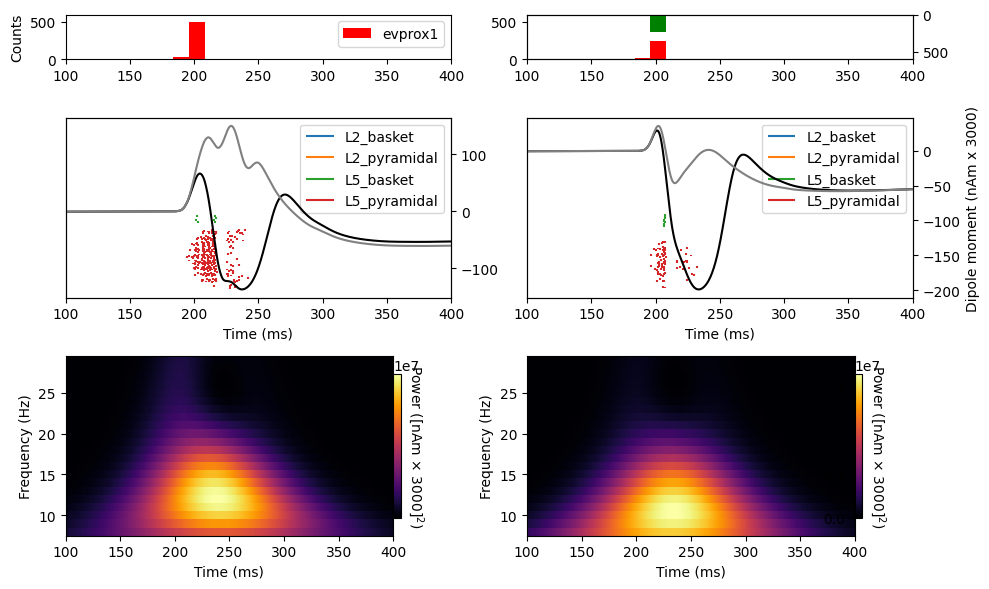

In [34]:
fig, ax = plt.subplots(3, 2, figsize=(10, 6), height_ratios=[0.25, 1, 1])

# proximal
net_prox.cell_response.plot_spikes_hist(ax=ax[0,0], color='r', show=False)
net_prox.cell_response.plot_spikes_raster(ax=ax[1,0], show=False)
ax2 = ax[1,0].twinx()
ax2.plot(dpl_prox[0].times, dpl_prox[0].data['agg'], color='black', lw=1.5)
ax2.plot(dpl_prox[0].times, dpl_prox_no_ca[0].data['agg'], color=[0.5, 0.5, 0.5], lw=1.5)
freqs = np.arange(8., 30., 1.)
dpl_prox[0].plot_tfr_morlet(freqs, n_cycles=5, tmin=0, ax=ax[2,0], show=False)
ax[0,0].set_ylim([0, 600])
# # distal
# ax[0,1].set_yticks([])
# ax1tw = ax[0,1].twinx()
# ax1tw.hist(spike_dist, bins, color='g')
# ax1tw.set_ylim([0, 600])
# ax1tw.invert_yaxis()
# net_dist.cell_response.plot_spikes_raster(ax=ax[1,1], show=False)
# ax2 = ax[1,1].twinx()
# ax2.plot(dpl_prox[0].times, dpl_dist[0].data['agg'], color='black', lw=1.5)
# ax2.plot(dpl_prox[0].times, dpl_dist_no_ca[0].data['agg'], color=[0.5, 0.5, 0.5], lw=1.5)
# freqs = np.arange(8., 30., 1.)
# dpl_dist[0].plot_tfr_morlet(freqs, n_cycles=5, tmin=0, ax=ax[2,1], show=False)

# coincidence
ax[0,1].hist(spike_coin_prox, bins, color='r')
ax[0,1].set_ylim([0, 600])
ax1tw = ax[0,1].twinx()
ax1tw.hist(spike_coin_dist, bins, color='g')
ax1tw.set_ylim([0, 600])
ax1tw.invert_yaxis()
net_coin.cell_response.plot_spikes_raster(ax=ax[1,1], show=False)
ax2 = ax[1,1].twinx()
ax2.plot(dpl_coin[0].times, dpl_coin[0].data['agg'], color='black', lw=1.5)
ax2.plot(dpl_coin[0].times, dpl_coin_no_ca[0].data['agg'], color=[0.5, 0.5, 0.5], lw=1.5)
ax2.set_ylabel(f'Dipole moment (nAm x {scaling_factor})')

freqs = np.arange(8., 30., 1.)
dpl_coin[0].plot_tfr_morlet(freqs, n_cycles=5, tmin=0, ax=ax[2,1], show=False)

ax = ax.ravel()

for a in ax:
    a.set_xlim([100, 400])
fig.tight_layout()

fig.savefig(op.join(pathfig, 'beta_event_new_model_new_conn.pdf'), dpi=300)
fig.savefig(op.join(pathfig, 'beta_event_new_model_new_conn.png'), dpi=300)